# **Text to Image**

In [ ]:
!pip install --quiet diffusers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 40.8 MB/s eta 0:00:00


In [ ]:
import torch
from diffusers import StableDiffusionPipeline, AutoencoderKL

repo = "IDKiro/sdxs-512-0.9"
seed = 42
weight_type = torch.float32     # or float16

# Load model.
pipe = StableDiffusionPipeline.from_pretrained(repo, torch_dtype=weight_type)

# use original VAE
# pipe.vae = AutoencoderKL.from_pretrained("IDKiro/sdxs-512-0.9/vae_large")

pipe.to("cuda")


In [64]:
PROMPT = '' # @param {type:"string"}

In [ ]:
PROMPT = "portrait photo of a cat"

# Ensure using 1 inference step and CFG set to 0.
image = pipe(
    PROMPT,
    num_inference_steps=1,
    guidance_scale=0,
    generator=torch.Generator(device="cuda").manual_seed(seed)
).images[0]

image.save("t2ioutput.png")


  0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
img = mpimg.imread("t2ioutput.png")
plt.imshow(img)
plt.axis('off')
plt.show()

# **Image to Image**


In [1]:
!pip install --quiet diffusers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 23.8 MB/s eta 0:00:00


In [13]:
import random
import requests
import numpy as np
from PIL import Image
import base64
from io import BytesIO

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import torch
import torchvision.transforms.functional as F
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline

In [ ]:
device = "cuda"   # Linux & Windows
weight_type = torch.float16  # torch.float16 works as well, but pictures seem to be a bit worse

controlnet = ControlNetModel.from_pretrained(
    "IDKiro/sdxs-512-dreamshaper-sketch", torch_dtype=weight_type
).to(device)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "IDKiro/sdxs-512-dreamshaper", controlnet=controlnet, torch_dtype=weight_type
)
pipe.to(device)

In [33]:
style_list = [
    {
        "name": "No Style",
        "prompt": "{prompt}",
    },
    {
        "name": "Manga",
        "prompt": "manga style {prompt} . vibrant, high-energy, detailed, iconic, Japanese comic style",
    },
]

In [32]:
DEFAULT_STYLE_NAME = "No Style"

In [31]:
styles = {k["name"]: k["prompt"] for k in style_list}
STYLE_NAMES = list(styles.keys())
MAX_SEED = np.iinfo(np.int32).max

In [30]:
styles[DEFAULT_STYLE_NAME]

'{prompt}'

Utility

In [34]:
def pil_image_to_data_url(img, format="PNG"):
    buffered = BytesIO()
    img.save(buffered, format=format)
    img_str = base64.b64encode(buffered.getvalue()).decode()
    return f"data:image/{format.lower()};base64,{img_str}"


def randomize_seed_fn(seed: int, randomize_seed: bool) -> int:
    if randomize_seed:
        seed = random.randint(0, MAX_SEED)
    return seed

Test Image

In [59]:
# RYAN_BLACK&WHITE = https://i.ibb.co/GWxJyxJ/Ryan-Reynolds-ezgif-com-webp-to-jpg-converter.jpg
# RYAN_COLOR = https://i.ibb.co/Bw9QrHR/ryan-color.jpg

In [60]:
URL = 'https://i.ibb.co/Bw9QrHR/ryan-color.jpg' # @param {type:"string"}

In [61]:
img_request = requests.get(URL)
image = Image.open(BytesIO(img_request.content))

In [62]:
def run(
    image,
    prompt,
    prompt_template,
    style_name,
    controlnet_conditioning_scale,
    device_type="GPU",
    param_dtype='torch.float16',
):
    if device_type == "CPU":
        device = "cpu"
        param_dtype = 'torch.float32'
    else:
        device = "cuda"

    pipe.to(torch_device=device, torch_dtype=torch.float16 if param_dtype == 'torch.float16' else torch.float32)

    print(f"prompt: {prompt}")

    if image is None:
        print("Image Not Loaded!")

    prompt = prompt_template.replace("{prompt}", prompt)
    control_image = image.convert("RGB")
    control_image = Image.fromarray(255 - np.array(control_image))

    output_pil = pipe(
        prompt=prompt,
        image=control_image,
        width=512,
        height=512,
        guidance_scale=0.0,
        num_inference_steps=1,
        num_images_per_prompt=1,
        output_type="pil",
        controlnet_conditioning_scale=controlnet_conditioning_scale,
    ).images[0]

    return (
        output_pil

    )

style = "Manga"
prompt_temp = "anime artwork {prompt} . anime style, key visual, vibrant, studio anime,  highly detailed"

controlnet_conditioning_scale = 0.95

device_choices = ['GPU','CPU']
dtype_choices = ['torch.float16','torch.float32']

device_type = 'GPU'
param_dtype = 'torch.float32'

prompt = ""

inputs = [image, prompt, prompt_temp, style, controlnet_conditioning_scale, device_type, param_dtype]


output = run(image, prompt, prompt_temp, style, controlnet_conditioning_scale, device_type, param_dtype)

output.save("i2ioutput.png")

prompt: 


  0%|          | 0/1 [00:00<?, ?it/s]

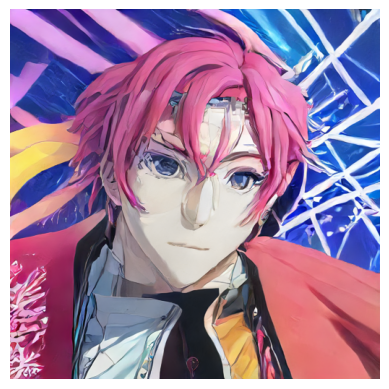

In [63]:
img = mpimg.imread("i2ioutput.png")
plt.imshow(img)
plt.axis('off')
plt.show()